In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

import shap

import random

seed = 42

random.seed(seed)
np.random.seed(seed)

from catboost import CatBoostRegressor

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from hyperopt import (
    fmin,
    tpe,
    hp,
    Trials,
    STATUS_OK
)

In [2]:
data = pd.read_csv("/home/aashr/-/Py/Minor_Spec/Papers/1-s2.0-S2666016424001440-mmc1.csv")
data

,ID,Type of MB,Types of contaminants,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,1,polypropylene (PP),2-(2-Butoxyethoxy)ethanol,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,2,polypropylene (PP),Caprolactam,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,3,polypropylene (PP),Creatine,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,4,polypropylene (PP),Formaldehyde,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,5,polypropylene (PP),Isopropanol,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,1903,Poly(p-phenylene oxide) (PPO),Indomethacin,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,1904,Poly(p-phenylene oxide) (PPO),Cephalexin hydrate,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,1905,Poly(p-phenylene oxide) (PPO),Diltiazem,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,1906,Poly(p-phenylene oxide) (PPO),Erythromycin,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [3]:
# data = data[[
#     "Compound Mw (g/mol)",
#     "Compound Kow",
#     "Pressure (kPa)",
#     "Measurement time (min)",
#     "Initial concentration of compound (mg/L)",
#     "min projection (Å)",
#     "max projection (Å)",
#     "MB MWCO (Da)",
#     "MB contact angle (°)",
#     "MB zeta potential",
#     "Compound charge",
#     "pH",
#     "removal rate (%)"
# ]].copy()

# data = data.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)
# data

In [4]:

# df = pd.get_dummies(data, columns=["Type of MB"])
# df = pd.get_dummies(df, columns=[ "Types of contaminants"])
# df = df.drop(columns=["ID"])

df = data.drop(columns=["ID", "Type of MB", "Types of contaminants"]) 
df

,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [5]:
# df = df.dropna()

In [6]:
len(df.columns)

15

In [7]:
# Paper-style 6-feature setup: keep the same exact variables used in the study
# and avoid any invalid log transform on negative Kow values.
Y = df["removal rate (%)"].astype(float)
X = df.drop(columns=["removal rate (%)"]).copy()

# Convert all features to numeric and keep only valid rows
X = X.apply(pd.to_numeric, errors="coerce")
Y = Y.loc[X.index]

print(X.head())
print("Shape:", X.shape)

    pH  Compound Mw (g/mol)  Compound charge  Compound Kow  \
0  7.0              162.229              0.0         0.711   
1  7.0              113.160              0.0         0.310   
2  7.0              131.135              0.0        -2.864   
3  7.0               30.026              0.0        -0.467   
4  7.0               60.096              0.0         0.255   

   min projection (Å)  max projection (Å)  MB MWCO (Da)  MB contact angle (°)  \
0                3.25                8.08           150                  50.0   
1                3.92                4.01           150                  50.0   
2                3.35                4.36           150                  50.0   
3                2.08                2.34           150                  50.0   
4                2.95                3.36           150                  50.0   

   MB zeta potential  Total charge  Pressure (kPa)  Measurement time (min)  \
0               -1.0           0.0           800.0            

In [8]:
# Keep the raw Compound Kow values. The paper dataset contains negative Kow values,
# so log10 would produce invalid values and distort the model.
X["Compound Kow"] = pd.to_numeric(X["Compound Kow"], errors="coerce")
# X = X.dropna()
Y = Y.loc[X.index]

print("Negative Kow count:", int((X["Compound Kow"] < 0).sum()))
print("Final X shape:", X.shape)

Negative Kow count: 319
Final X shape: (1906, 14)


In [9]:
X

,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798


In [10]:
# view = data.drop(columns=["Type of MB", "Types of contaminants"])
print(df.min())
print(df.max())


pH                                            2.20000
Compound Mw (g/mol)                          30.02600
Compound charge                              -2.00000
Compound Kow                                 -6.30000
min projection (Å)                            2.08000
max projection (Å)                            2.34000
MB MWCO (Da)                                 65.00000
MB contact angle (°)                         14.40000
MB zeta potential                            -1.00000
Total charge                                 -1.99610
Pressure (kPa)                              240.00000
Measurement time (min)                       10.00000
Initial concentration of compound (mg/L)      0.00072
compound size (nm)                            0.22100
removal rate (%)                              0.00000
dtype: float64
pH                                            11.0000
Compound Mw (g/mol)                          837.0580
Compound charge                                1.8281
Compound Kow 

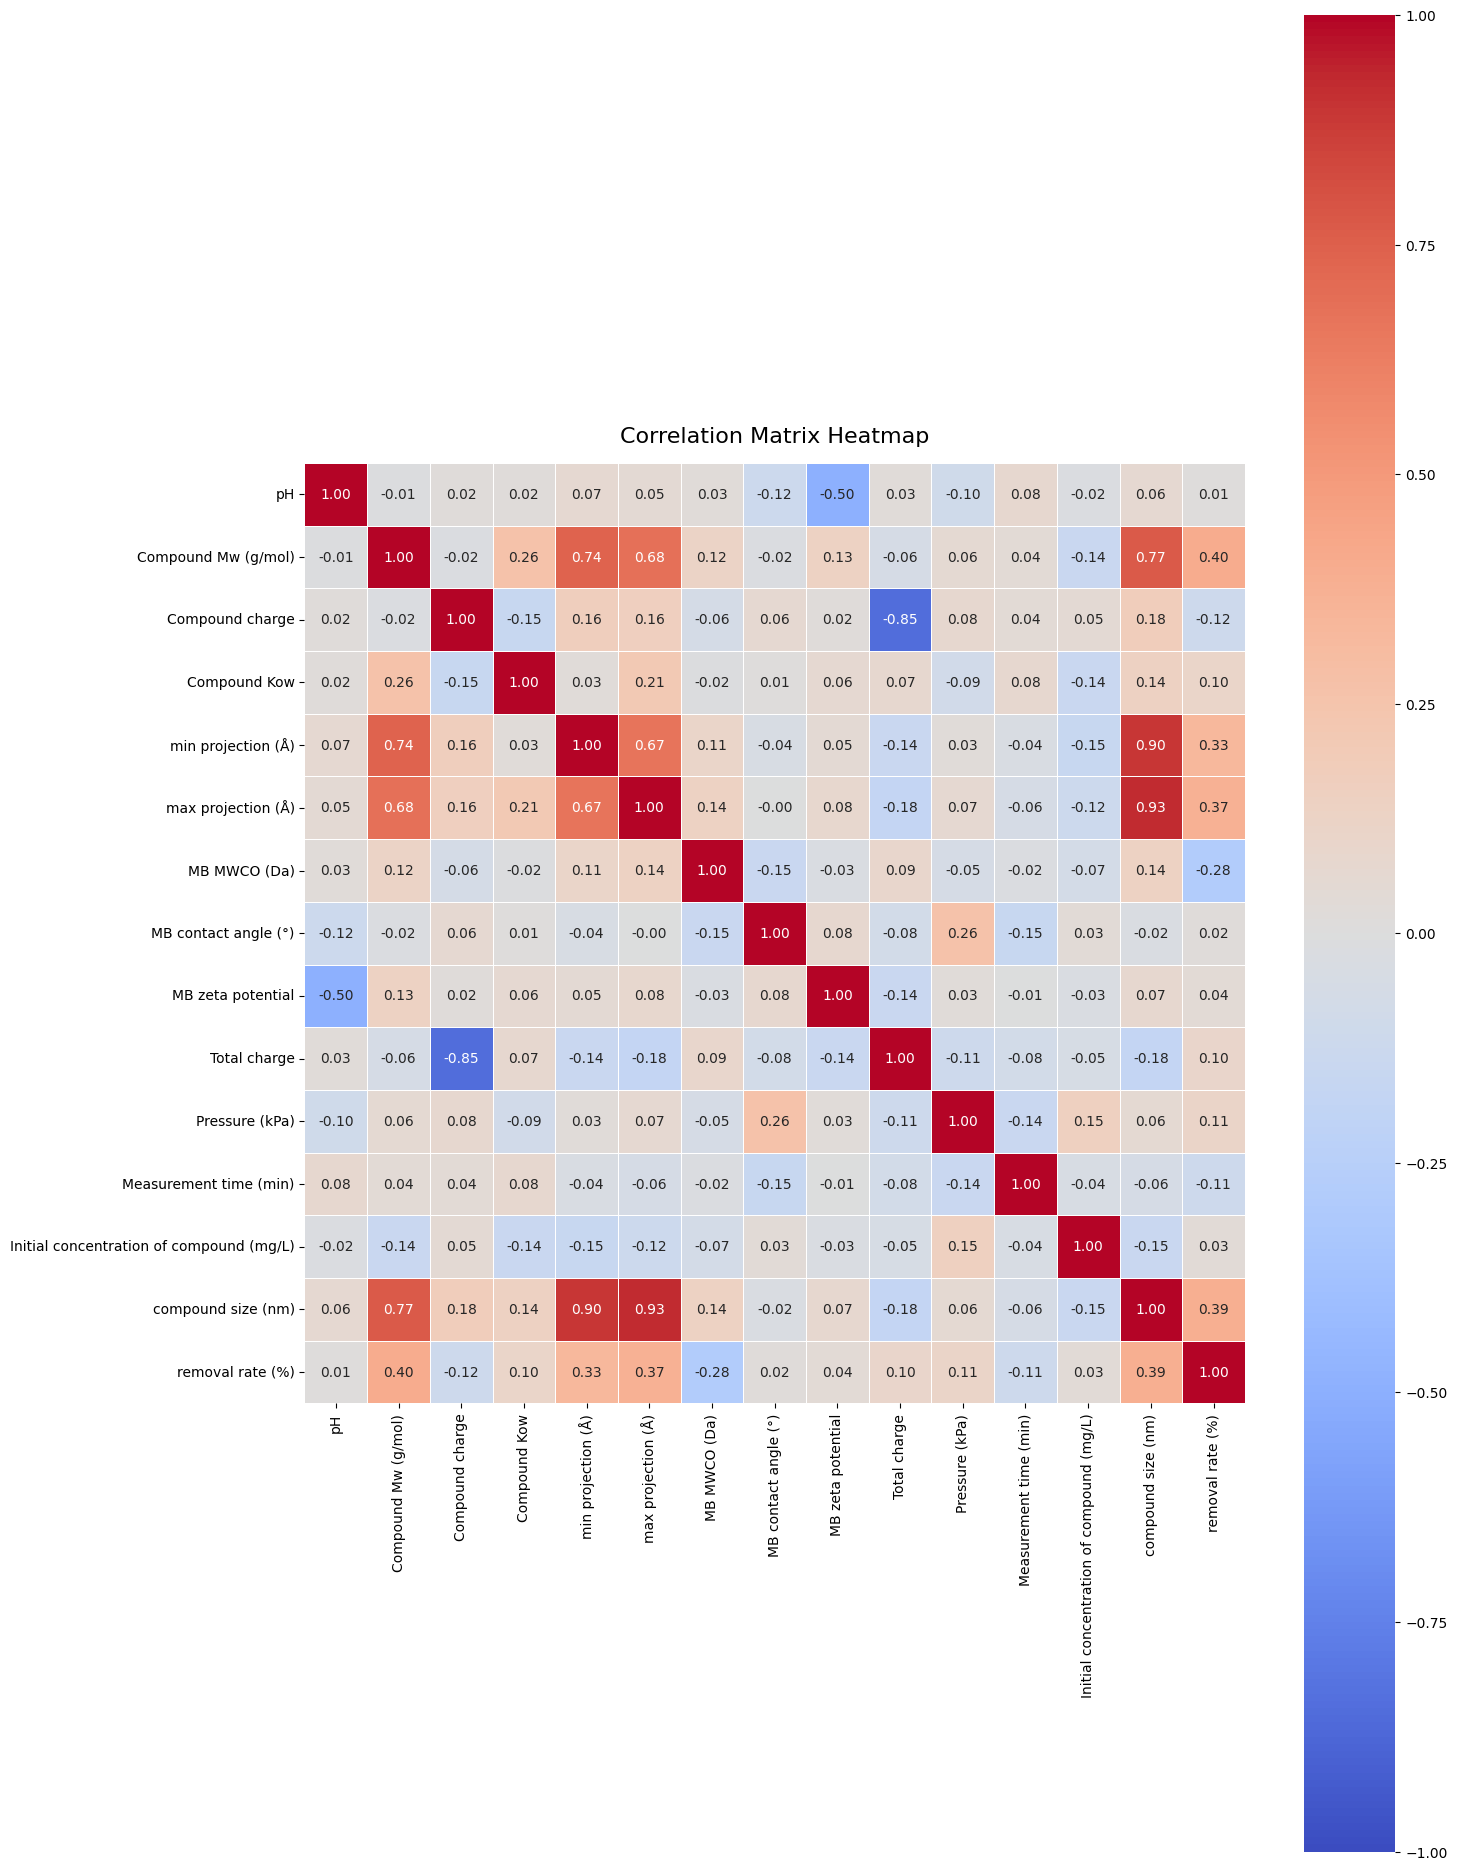

In [11]:
df_num = df.select_dtypes(include=[np.number])
corr = df_num.corr()
# 3. Create a clean heatmap
plt.figure(figsize=(15, 19))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Matrix Heatmap", fontsize=16, pad=15)
plt.tight_layout()
plt.show()

In [12]:
# from scipy import stats
# import numpy as np

# z = np.abs(stats.zscore(X))
# mask = (z < 3).all(axis=1)

# X = X[mask]
# Y = Y[mask]
# X

In [13]:
X = X.replace([np.inf, -np.inf], np.nan)
valid_idx = X.dropna().index
X = X.loc[valid_idx]
Y = Y.loc[valid_idx]

In [14]:
print(X.shape)
X

(1906, 14)


,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape) 


Train shape: (1524, 14)
Test shape: (382, 14)


In [16]:
param_space = {
    "iterations": hp.quniform("iterations", 100, 600, 50),
    "depth": hp.quniform("depth", 4, 8, 1),
    "learning_rate": hp.loguniform(
        "learning_rate",
        np.log(0.01),
        np.log(0.2)
    ),
    "l2_leaf_reg": hp.loguniform(
        "l2_leaf_reg",
        np.log(1),
        np.log(20)
    ),
    "random_strength": hp.uniform(
        "random_strength",
        0,
        2
    ),
    "bagging_temperature": hp.uniform(
        "bagging_temperature",
        0,
        2
    )
}


def objective(params):
    params["iterations"] = int(params["iterations"])
    params["depth"] = int(params["depth"])

    kf = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = []

    for train_idx, val_idx in kf.split(X_train):
        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = CatBoostRegressor(
            loss_function="RMSE",
            bootstrap_type="Bayesian",
            random_seed=42,
            verbose=False,
            task_type="GPU",
            devices="0",
            **params
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
        scores.append(r2_score(y_val, pred))

    mean_r2 = np.mean(scores)

    return {
        "loss": -mean_r2,
        "status": STATUS_OK
    }

In [17]:
print("Starting CatBoost Hyperopt optimization...")

trials = Trials()

best_params = fmin(
    fn=objective,
    space=param_space,
    algo=tpe.suggest,
    max_evals=50,
    trials=trials,
    rstate=np.random.default_rng(42)
)

print("\n--- Optimization Complete ---")

Starting CatBoost Hyperopt optimization...
100%|██████████| 50/50 [12:31<00:00, 15.03s/trial, best loss: -0.8061758572410618]

--- Optimization Complete ---


In [18]:
best_params["iterations"] = int(
    best_params["iterations"]
)

best_params["depth"] = int(
    best_params["depth"]
)

best_cv_score = -trials.best_trial["result"]["loss"]
print("Best Parameters:")
print(best_params)

print(
    f"Best CV R² Score: "
    f"{best_cv_score:.4f}"
)

Best Parameters:
{'bagging_temperature': np.float64(0.6985138936705428), 'depth': 8, 'iterations': 400, 'l2_leaf_reg': np.float64(1.1758635734286662), 'learning_rate': np.float64(0.1008299569517736), 'random_strength': np.float64(1.4465968073487212)}
Best CV R² Score: 0.8062


In [19]:
final_cat_model = CatBoostRegressor(
    loss_function="RMSE",
    bootstrap_type="Bayesian",
    random_seed=42,
    task_type="GPU",
    devices="0",
    verbose=False,
    **best_params
)

final_cat_model.fit(
    X_train,
    y_train
)

CatBoostRegressor(bagging_temperature=np.float64(0.6985138936705428), bootstrap_type='Bayesian', depth=8, devices='0', iterations=400, l2_leaf_reg=np.float64(1.1758635734286662), learning_rate=np.float64(0.1008299569517736), loss_function='RMSE', random_seed=42, random_strength=np.float64(1.4465968073487212), task_type='GPU', verbose=False)

In [20]:
cat_pred = final_cat_model.predict(
    X_test
)

cat_mse = mean_squared_error(
    y_test,
    cat_pred
)

cat_rmse = np.sqrt(cat_mse)

cat_mae = mean_absolute_error(
    y_test,
    cat_pred
)

cat_r2 = r2_score(
    y_test,
    cat_pred
)

print("\n--- CatBoost Final Test Set Metrics ---")

print(f"MSE: {cat_mse:.4f}")
print(f"RMSE: {cat_rmse:.4f}")
print(f"MAE: {cat_mae:.4f}")
print(f"R² Score: {cat_r2:.4f}")


--- CatBoost Final Test Set Metrics ---
MSE: 129.7119
RMSE: 11.3891
MAE: 7.4298
R² Score: 0.8301


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
/tmp/ipykernel_4687/518697080.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test)


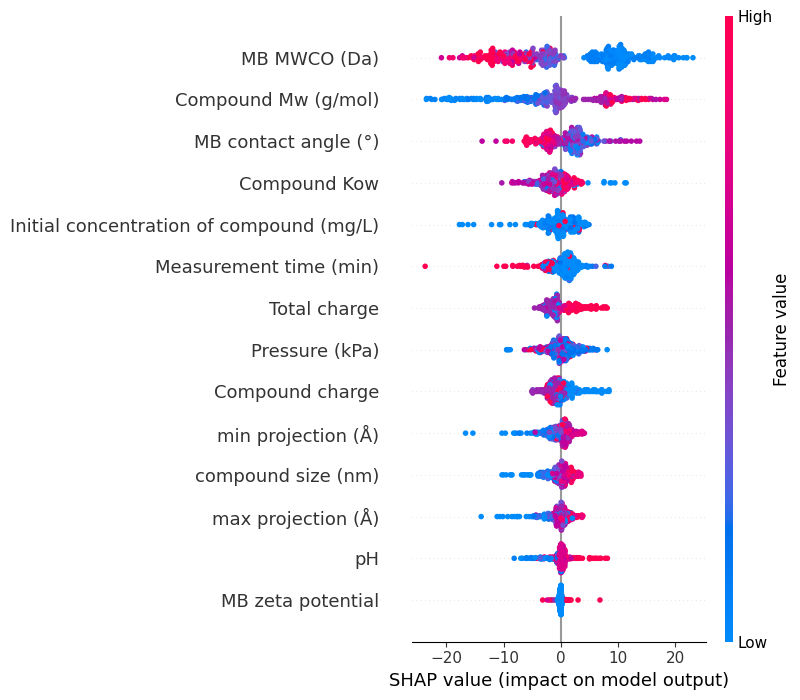

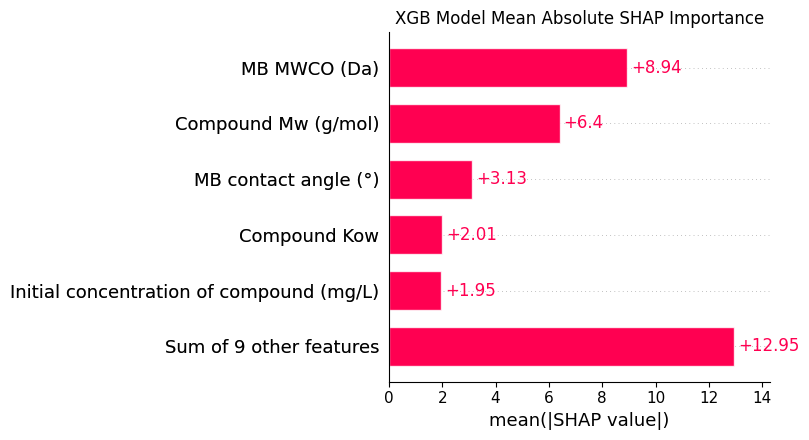


--- Top 6 Most Important Features ---
                                     feature  importance
6                               MB MWCO (Da)    8.935948
1                        Compound Mw (g/mol)    6.401597
7                       MB contact angle (°)    3.129701
3                               Compound Kow    2.007126
12  Initial concentration of compound (mg/L)    1.948078
11                    Measurement time (min)    1.929465


In [21]:
background = shap.sample(
    X_train,
    200,
    random_state=42
)

explainer = shap.TreeExplainer(final_cat_model, data=background, feature_perturbation="interventional")
shap_values = explainer(X_test)  # Using the new explainer API format

# Summary Plot
shap.summary_plot(shap_values, X_test)

# Bar Plot
shap.plots.bar(shap_values, max_display=6, show=False)
plt.title("XGB Model Mean Absolute SHAP Importance")
plt.tight_layout()
plt.show()

# FIXED: Extract mean absolute values correctly from the SHAP Explanation object
shap_importance = np.abs(shap_values.values).mean(axis=0)

feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance": shap_importance
}).sort_values(by="importance", ascending=False)

top6 = feature_importance.head(6)
print("\n--- Top 6 Most Important Features ---")
print(top6)

In [22]:
shap_train = explainer(
    X_train
)


# Mean absolute SHAP
train_shap_importance = np.abs(
    shap_train.values
).mean(axis=0)


cat_train_importance = pd.DataFrame({

    "feature": X_train.columns,

    "importance": train_shap_importance

}).sort_values(

    by="importance",
    ascending=False

)


print(
    "\n--- CatBoost Training SHAP Importance ---"
)

print(
    cat_train_importance
)


# Extract Top-6
cat_top6_features = (

    cat_train_importance
    .head(6)["feature"]
    .tolist()

)


print(
    "\n--- CatBoost SHAP Top-6 Features ---"
)

for rank, feature in enumerate(
    cat_top6_features,
    start=1
):

    print(
        f"{rank}. {feature}"
    )

 99%|===================| 1504/1524 [00:43<00:00]        


--- CatBoost Training SHAP Importance ---
                                     feature  importance
6                               MB MWCO (Da)    8.713340
1                        Compound Mw (g/mol)    6.069655
7                       MB contact angle (°)    3.118680
3                               Compound Kow    2.143575
11                    Measurement time (min)    2.124835
12  Initial concentration of compound (mg/L)    1.921808
9                               Total charge    1.918650
10                            Pressure (kPa)    1.874163
2                            Compound charge    1.733952
4                         min projection (Å)    1.612452
5                         max projection (Å)    1.488229
13                        compound size (nm)    1.427978
0                                         pH    0.971478
8                          MB zeta potential    0.213371

--- CatBoost SHAP Top-6 Features ---
1. MB MWCO (Da)
2. Compound Mw (g/mol)
3. MB contact angle (°)
4